# Laboratorio Evaluativo 2 — Energía · planta de procesos
**Dúo 08 · Conserva del Maule**  
Empresa: Conserva del Maule

Período de análisis: Mayo a agosto de 2026

Asignatura: Ciencia de Datos

Pregunta de la gerencia

¿Es la Línea Pulpa la que tiene mayor costo de energía por kilo producido?

Indicador

Costo energético por kilogramo (CLP/kg) = Costo energético total en CLP / Producción total en kg.

Grano de la tabla analítica

Una fila representa una orden de producción, con sus cargos energéticos acumulados y su producción asociada.


In [1]:
# Importar las librerías
import pandas as pd
import numpy as np
import json
import re

from pathlib import Path

In [2]:
# Cargar los cuatro archivos
ruta = Path(".")

A = pd.read_csv(
    ruta / "A_cargos_energia.csv",
    sep=";",
    dtype="string",
    keep_default_na=False
)

B = pd.read_csv(
    ruta / "B_registros_produccion.csv",
    sep=",",
    dtype="string",
    keep_default_na=False
)

maestro = pd.read_csv(
    ruta / "maestro_lineas.csv",
    sep=";",
    dtype="string",
    keep_default_na=False
)

with open(ruta / "C_dolar_observado.json",
          encoding="utf-8") as archivo:
    C = json.load(archivo)

print("Archivo A:", A.shape)
print("Archivo B:", B.shape)
print("Maestro:", maestro.shape)
print("Registros de dólar:", len(C["serie"]))

Archivo A: (641, 13)
Archivo B: (595, 7)
Maestro: (5, 5)
Registros de dólar: 104


In [3]:
# Inspeccionar las primeras filas
display(A.head())
display(B.head())
display(maestro.head())
display(pd.DataFrame(C["serie"]).head())

,op,linea,fecha_doc,cod_linea,concepto,cantidad,precio_unitario,moneda,monto,estado,fecha_pago,fecha_carga,observacion
0,OP-1005,1,2026-07-14,LN-04,Vapor de caldera,5,"162,79",USD,"813,95",Pagada,2026-08-13,2026-07-15 08:26,
1,OP-1005,2,2026-07-14,LN-04,Electricidad,64,1242,CLP,79488,Pagada,2026-08-13,2026-07-15 11:09,
2,OP-1006,2,2026-07-21,LN-03,Agua de proceso,39,17268,CLP,673452,Pagada,2026-08-19,2026-07-22 11:25,
3,OP-1006,1,2026-07-21,LN-03,Electricidad,1,"376,26",USD,"376,26",Pagada,2026-08-19,2026-07-22 16:53,
4,OP-1011,2,2026-08-29,LN-03,Electricidad,34,13416,CLP,456144,Pendiente,,2026-08-30 15:08,


,id_registro,ref_op,fecha_hora,turno,medida,unidad,observacion
0,R-52135,1115,2026-05-04 09:27,Día,6260.77,kg,
1,R-52242,1193,2026-05-04 10:09,Día,8867.84,kg,
2,R-52636,1491,2026-05-04 10:52,Día,10.42,ton,
3,R-52137,1115,2026-05-04 11:23,Día,4374.96,kg,
4,R-52637,1491,2026-05-04 12:55,Día,6423.39,kg,


,codigo,nombre,codigo_anterior,vigente_desde,observacion
0,LN-01,Línea Tomate,LN-01,2026-06-15,
1,LN-02,Línea Durazno,LN-07,2026-06-15,recodificado
2,LN-03,Línea Pera,LN-02,2026-06-15,recodificado
3,LN-04,Línea Mixta,LN-04,2026-06-15,
4,LN-05,Línea Pulpa,LN-05,2026-06-15,


,fecha,valor
0,2026-09-30T03:00:00.000Z,951.20
1,2026-09-29T03:00:00.000Z,949.40
2,2026-09-28T03:00:00.000Z,954.46
3,2026-09-25T03:00:00.000Z,956.17
4,2026-09-24T03:00:00.000Z,953.99


In [4]:
# Diagnosticar tipos de datos y faltantes
print("TIPOS DE DATOS DE A")
print(A.dtypes)

print("\nTIPOS DE DATOS DE B")
print(B.dtypes)

print("\nFALTANTES VACÍOS DE A")
print(A.eq("").sum())

print("\nFALTANTES VACÍOS DE B")
print(B.eq("").sum())

TIPOS DE DATOS DE A
op                 string
linea              string
fecha_doc          string
cod_linea          string
concepto           string
cantidad           string
precio_unitario    string
moneda             string
monto              string
estado             string
fecha_pago         string
fecha_carga        string
observacion        string
dtype: object

TIPOS DE DATOS DE B
id_registro    string
ref_op         string
fecha_hora     string
turno          string
medida         string
unidad         string
observacion    string
dtype: object

FALTANTES VACÍOS DE A
op                   0
linea                0
fecha_doc            0
cod_linea            0
concepto             0
cantidad             0
precio_unitario      0
moneda               0
monto                0
estado               0
fecha_pago         234
fecha_carga          0
observacion        637
dtype: Int64

FALTANTES VACÍOS DE B
id_registro      0
ref_op           0
fecha_hora       0
turno            0
medid

In [5]:
# Revisar categorías y valores distintos
print("ESTADOS DE LOS DOCUMENTOS")
print(A["estado"].value_counts())

print("\nMONEDAS")
print(A["moneda"].value_counts())

print("\nCÓDIGOS DE LÍNEA")
print(A["cod_linea"].value_counts())

print("\nUNIDADES DE PRODUCCIÓN")
print(B["unidad"].value_counts())

print("\nCONCEPTOS DE COSTO")
print(A["concepto"].value_counts())

ESTADOS DE LOS DOCUMENTOS
estado
Pagada       407
Pendiente    169
Anulada       65
Name: count, dtype: Int64

MONEDAS
moneda
CLP    449
USD    192
Name: count, dtype: Int64

CÓDIGOS DE LÍNEA
cod_linea
LN-01     127
LN-02     108
LN-05     100
LN-04      95
LN-03      53
LN-07      24
 LN-05     10
ln-01      10
LN05       10
ln-02       9
LN-09       8
LN02        7
LN-5        7
LN-3        7
LN-2        6
 LN-02      6
 LN-04      6
 LN-01      5
LN01        5
ln-04       5
LN04        5
LN-1        5
LN07        4
LN-4        4
ln-07       3
ln-05       3
ln-03       3
LN-7        2
LN03        2
 LN-03      1
 LN-07      1
Name: count, dtype: Int64

UNIDADES DE PRODUCCIÓN
unidad
kg     571
ton     24
Name: count, dtype: Int64

CONCEPTOS DE COSTO
concepto
Vapor de caldera    142
Gas natural         141
Agua de proceso     126
Electricidad        119
Aire comprimido     113
Name: count, dtype: Int64


In [6]:
# Limpieza del archivo A
# Crear copias de trabajo
a = A.copy()
b = B.copy()

print("Registros originales de A:", len(a))
print("Registros originales de B:", len(b))

Registros originales de A: 641
Registros originales de B: 595


In [7]:
# Crear una función para convertir números
def convertir_numero(valor):

    texto = str(valor).strip()

    if texto.lower() in [
        "", "nan", "none", "n/a",
        "s/i", "—", "-", "null"
    ]:
        return np.nan

    texto = texto.replace("$", "")
    texto = texto.replace(" ", "")

    if "," in texto:
        texto = texto.replace(".", "")
        texto = texto.replace(",", ".")

    try:
        return float(texto)
    except ValueError:
        return np.nan

In [8]:
# Aplicar la conversión
a["cantidad_n"] = a["cantidad"].apply(convertir_numero)

a["precio_n"] = a["precio_unitario"].apply(
    convertir_numero
)

a["monto_n"] = a["monto"].apply(convertir_numero)

display(
    a[[
        "cantidad", "cantidad_n",
        "precio_unitario", "precio_n",
        "monto", "monto_n"
    ]].head(10)
)

,cantidad,cantidad_n,precio_unitario,precio_n,monto,monto_n
0,5,5.0,"162,79",162.79,"813,95",813.95
1,64,64.0,1242,1242.00,79488,79488.00
2,39,39.0,17268,17268.00,673452,673452.00
3,1,1.0,"376,26",376.26,"376,26",376.26
4,34,34.0,13416,13416.00,456144,456144.00
5,10,10.0,"36,12",36.12,"361,20",361.20
6,110,110.0,558,558.00,61380,61380.00
7,8,8.0,8455,8455.00,67640,67640.00
8,83,83.0,15053,15053.00,1249399,1249399.00
9,9,9.0,"44,23",44.23,"398,07",398.07


In [9]:
# Normalizar las fechas
def convertir_fecha(valor):

    texto = str(valor).strip()

    if texto == "":
        return pd.NaT

    if "/" in texto:
        return pd.to_datetime(
            texto,
            format="%d/%m/%Y",
            errors="coerce"
        )

    return pd.to_datetime(
        texto,
        errors="coerce"
    )


a["fecha_doc_dt"] = a["fecha_doc"].apply(
    convertir_fecha
)

a["fecha_pago_dt"] = a["fecha_pago"].apply(
    convertir_fecha
)

a["fecha_carga_dt"] = pd.to_datetime(
    a["fecha_carga"],
    errors="coerce"
)

display(
    a[[
        "fecha_doc", "fecha_doc_dt",
        "fecha_pago", "fecha_pago_dt"
    ]].head()
)

,fecha_doc,fecha_doc_dt,fecha_pago,fecha_pago_dt
0,2026-07-14,2026-07-14,2026-08-13,2026-08-13
1,2026-07-14,2026-07-14,2026-08-13,2026-08-13
2,2026-07-21,2026-07-21,2026-08-19,2026-08-19
3,2026-07-21,2026-07-21,2026-08-19,2026-08-19
4,2026-08-29,2026-08-29,,NaT


In [10]:
# Detectar duplicados del archivo A
# Reglas R1 y R2
a["duplicada_llave"] = a.duplicated(
    subset=["op", "linea"],
    keep=False
)

duplicados_A = a[a["duplicada_llave"]]

print("Registros involucrados en duplicados:",
      len(duplicados_A))

display(
    duplicados_A.sort_values(
        ["op", "linea", "fecha_carga_dt"]
    )
)

Registros involucrados en duplicados: 16


,op,linea,fecha_doc,cod_linea,concepto,cantidad,precio_unitario,moneda,monto,estado,fecha_pago,fecha_carga,observacion,cantidad_n,precio_n,monto_n,fecha_doc_dt,fecha_pago_dt,fecha_carga_dt,duplicada_llave
32,OP-1062,3,2026-07-13,LN-05,Vapor de caldera,3,"199,76",USD,"599,28",Pagada,2026-08-08,2026-07-14 08:53,,3.0,199.76,599.28,2026-07-13,2026-08-08,2026-07-14 08:53:00,True
31,OP-1062,3,2026-07-13,LN-05,Vapor de caldera,3,"199,76",USD,"599,28",Pagada,2026-08-08,2026-07-26 08:53,,3.0,199.76,599.28,2026-07-13,2026-08-08,2026-07-26 08:53:00,True
42,OP-1079,5,2026-05-23,LN-01,Vapor de caldera,111,2141,CLP,237651,Pendiente,,2026-05-24 13:40,,111.0,2141.00,237651.00,2026-05-23,NaT,2026-05-24 13:40:00,True
39,OP-1079,5,2026-05-23,LN-01,Vapor de caldera,111,2141,CLP,237651,Pendiente,,2026-06-05 13:40,,111.0,2141.00,237651.00,2026-05-23,NaT,2026-06-05 13:40:00,True
98,OP-1162,5,2026-05-07,LN-01,Electricidad,10,"19,20",USD,"192,00",Pagada,1900-01-01,2026-05-08 17:20,,10.0,19.20,192.00,2026-05-07,1900-01-01,2026-05-08 17:20:00,True
100,OP-1162,5,2026-05-07,LN-01,Electricidad,10,"19,20",USD,"192,00",Pagada,1900-01-01,2026-05-20 17:20,,10.0,19.20,192.00,2026-05-07,1900-01-01,2026-05-20 17:20:00,True
199,OP-1272,3,2026-08-18,LN-02,Gas natural,5,"54,69",USD,"295,33",Pagada,2026-09-09,2026-08-19 11:28,,5.0,54.69,295.33,2026-08-18,2026-09-09,2026-08-19 11:28:00,True
201,OP-1272,3,2026-08-18,LN-02,Gas natural,5,"54,69",USD,"273,45",Pagada,2026-09-09,2026-08-22 13:28,corrige monto según factura,5.0,54.69,273.45,2026-08-18,2026-09-09,2026-08-22 13:28:00,True
224,OP-1293,4,2026-07-14,LN-04,Electricidad,8,"26,18",USD,"209,44",Pendiente,,2026-07-15 16:52,,8.0,26.18,209.44,2026-07-14,NaT,2026-07-15 16:52:00,True
223,OP-1293,4,2026-07-14,LN-04,Electricidad,8,"26,18",USD,"209,44",Pendiente,,2026-07-27 16:52,,8.0,26.18,209.44,2026-07-14,NaT,2026-07-27 16:52:00,True


In [11]:
# Conservar la fecha_carga más reciente
a = a.sort_values(
    "fecha_carga_dt",
    kind="stable"
)

a = a.drop_duplicates(
    subset=["op", "linea"],
    keep="last"
).copy()

print("Filas originales:", len(A))
print("Filas después de R2:", len(a))

Filas originales: 641
Filas después de R2: 633


In [12]:
# Normalizar los códigos
def normalizar_codigo(valor):

    texto = str(valor).strip().upper()
    texto = texto.replace(" ", "")

    patron = re.fullmatch(
        r"LN-?0*(\d+)",
        texto
    )

    if patron:
        numero = patron.group(1)
        return "LN-" + numero.zfill(2)

    return None


a["cod_normalizado"] = a["cod_linea"].apply(
    normalizar_codigo
)

display(
    a[["cod_linea", "cod_normalizado"]]
    .drop_duplicates()
    .sort_values("cod_linea")
)

,cod_linea,cod_normalizado
39,LN-01,LN-01
188,LN-02,LN-02
4,LN-03,LN-03
611,LN-04,LN-04
395,LN-05,LN-05
133,LN-07,LN-07
72,LN-01,LN-01
126,LN-02,LN-02
429,LN-03,LN-03
623,LN-04,LN-04


In [13]:
# Integrar el maestro de líneas
display(maestro)

maestro["vigente_desde_dt"] = pd.to_datetime(
    maestro["vigente_desde"]
)

fecha_cambio = pd.Timestamp("2026-06-15")

codigos_actuales = dict(
    zip(maestro["codigo"], maestro["nombre"])
)

codigos_anteriores = dict(
    zip(maestro["codigo_anterior"], maestro["nombre"])
)

,codigo,nombre,codigo_anterior,vigente_desde,observacion
0,LN-01,Línea Tomate,LN-01,2026-06-15,
1,LN-02,Línea Durazno,LN-07,2026-06-15,recodificado
2,LN-03,Línea Pera,LN-02,2026-06-15,recodificado
3,LN-04,Línea Mixta,LN-04,2026-06-15,
4,LN-05,Línea Pulpa,LN-05,2026-06-15,


In [14]:
# Identificar la línea considerando la fecha del documento

def identificar_linea(fila):
    fecha = fila["fecha_doc_dt"]
    codigo = fila["cod_normalizado"]

    if pd.isna(fecha) or codigo is None:
        return None

    if fecha < fecha_cambio:
        return codigos_anteriores.get(codigo)

    return codigos_actuales.get(codigo)


a["nombre_linea"] = a.apply(
    identificar_linea,
    axis=1
)

a["codigo_no_corresponde"] = (
    a["nombre_linea"].isna()
)

print("Cargos sin línea identificable:")
print(a["codigo_no_corresponde"].sum())


Cargos sin línea identificable:
8


### Validación de los códigos históricos

Se comprobó que algunos códigos de línea cambiaron de significado a partir del 15 de junio de 2026.

Por esta razón, se utilizó el maestro de líneas junto con la fecha del documento para identificar correctamente cada proceso.

De esta manera, se evita asignar costos a una línea equivocada únicamente porque los códigos coinciden.

In [15]:
# Comparar códigos anteriores y vigentes

comparacion_codigos = maestro[
    ["nombre", "codigo_anterior", "codigo", "vigente_desde"]
].copy()

display(comparacion_codigos)

# Ejemplo de un código cuyo significado cambió
codigo_ejemplo = "LN-02"

print("Código:", codigo_ejemplo)

print(
    "Antes del cambio:",
    codigos_anteriores.get(codigo_ejemplo)
)

print(
    "Después del cambio:",
    codigos_actuales.get(codigo_ejemplo)
)

# Registros reales del archivo A con ese código
ejemplo_historico = a[
    a["cod_normalizado"] == codigo_ejemplo
][[
    "op", "fecha_doc_dt",
    "cod_linea", "nombre_linea"
]]

display(
    ejemplo_historico.sort_values("fecha_doc_dt").head(15)
)


,nombre,codigo_anterior,codigo,vigente_desde
0,Línea Tomate,LN-01,LN-01,2026-06-15
1,Línea Durazno,LN-07,LN-02,2026-06-15
2,Línea Pera,LN-02,LN-03,2026-06-15
3,Línea Mixta,LN-04,LN-04,2026-06-15
4,Línea Pulpa,LN-05,LN-05,2026-06-15


Código: LN-02
Antes del cambio: Línea Pera
Después del cambio: Línea Durazno


,op,fecha_doc_dt,cod_linea,nombre_linea
138,OP-1205,2026-05-04,ln-02,Línea Pera
125,OP-1193,2026-05-04,ln-02,Línea Pera
126,OP-1193,2026-05-04,LN-02,Línea Pera
137,OP-1205,2026-05-04,ln-02,Línea Pera
127,OP-1193,2026-05-04,LN-02,Línea Pera
124,OP-1193,2026-05-04,LN-02,Línea Pera
123,OP-1193,2026-05-04,LN-02,Línea Pera
136,OP-1205,2026-05-04,LN-02,Línea Pera
190,OP-1254,2026-05-08,ln-02,Línea Pera
189,OP-1254,2026-05-08,LN-02,Línea Pera


In [16]:
# Verificar R4: consistencia de montos
a["monto_calculado"] = (
    a["cantidad_n"] * a["precio_n"]
)

a["diferencia_pct"] = (
    (a["monto_n"] - a["monto_calculado"]).abs()
    / a["monto_calculado"].abs()
)

a.loc[
    a["monto_calculado"] <= 0,
    "diferencia_pct"
] = np.nan

a["r4_invalida"] = (
    a["diferencia_pct"] > 0.01
).fillna(False)

print("Cargos fuera de tolerancia R4:")
print(a["r4_invalida"].sum())

Cargos fuera de tolerancia R4:
36


In [17]:
# Identificar montos incompletos
a["r4_sin_datos"] = (
    a[["cantidad_n", "precio_n", "monto_n"]]
    .isna()
    .any(axis=1)
    |
    (a["monto_calculado"] <= 0)
)

print("Cargos sin datos suficientes:")
print(a["r4_sin_datos"].sum())

display(
    a.loc[
        a["r4_sin_datos"],
        ["op", "linea", "cantidad",
         "precio_unitario", "monto"]
    ]
)

Cargos sin datos suficientes:
6


,op,linea,cantidad,precio_unitario,monto
101,OP-1162,4,s/i,1336,45424
177,OP-1246,1,s/i,3929,282888
428,OP-1644,1,84,Por definir,413532
335,OP-1488,2,63,Por definir,99036
390,OP-1556,1,23,Por definir,862707
301,OP-1430,1,s/i,4963,545930


In [18]:
# Revisar los estados de los documentos
# Regla R5
print(a["estado"].value_counts())

a["r5_anulada"] = a["estado"] == "Anulada"

a["estado_valido"] = a["estado"].isin([
    "Pagada", "Pendiente", "Anulada"
])

display(
    a.groupby("estado").agg(
        documentos=("op", "size"),
        monto_registrado=("monto_n", "sum")
    )
)

estado
Pagada       403
Pendiente    165
Anulada       65
Name: count, dtype: Int64


,documentos,monto_registrado
estado,,
Anulada,65,1.370924e+07
Pagada,403,8.162298e+07
Pendiente,165,3.118072e+07


In [19]:
# Verificar R6 y R7: fechas
a["documento_domingo"] = (
    a["fecha_doc_dt"].dt.dayofweek == 6
)

a["r7_pago_invalido"] = (
    a["fecha_pago_dt"].notna()
    &
    a["fecha_doc_dt"].notna()
    &
    (
        a["fecha_pago_dt"] <
        a["fecha_doc_dt"]
    )
)

print("Documentos fechados en domingo:")
print(a["documento_domingo"].sum())

print("Pagos anteriores al documento:")
print(a["r7_pago_invalido"].sum())

Documentos fechados en domingo:
4
Pagos anteriores al documento:
19


In [20]:
# Convertir el JSON en una tabla
c = pd.DataFrame(C["serie"])

print("Cantidad de observaciones:", len(c))

display(c.head())

Cantidad de observaciones: 104


,fecha,valor
0,2026-09-30T03:00:00.000Z,951.20
1,2026-09-29T03:00:00.000Z,949.40
2,2026-09-28T03:00:00.000Z,954.46
3,2026-09-25T03:00:00.000Z,956.17
4,2026-09-24T03:00:00.000Z,953.99


In [21]:
# Convertir las fechas UTC a horario chileno
c["fecha_dolar"] = (
    pd.to_datetime(c["fecha"], utc=True)
    .dt.tz_convert("America/Santiago")
    .dt.normalize()
    .dt.tz_localize(None)
)

c["valor"] = pd.to_numeric(
    c["valor"],
    errors="coerce"
)

c = c.sort_values("fecha_dolar")

c = c.drop_duplicates(
    "fecha_dolar",
    keep="last"
)

display(c.head())

,fecha,valor,fecha_dolar
103,2026-05-04T04:00:00.000Z,891.02,2026-05-04
102,2026-05-05T04:00:00.000Z,892.87,2026-05-05
101,2026-05-06T04:00:00.000Z,889.79,2026-05-06
100,2026-05-07T04:00:00.000Z,888.89,2026-05-07
99,2026-05-08T04:00:00.000Z,893.59,2026-05-08


In [22]:
# Relacionar cada documento con su dólar
# Regla R8
a = a.sort_values("fecha_doc_dt")

a = pd.merge_asof(
    a,
    c[["fecha_dolar", "valor"]],
    left_on="fecha_doc_dt",
    right_on="fecha_dolar",
    direction="backward"
)

a["dolar_arrastrado"] = (
    a["fecha_dolar"].notna()
    &
    (
        a["fecha_doc_dt"] !=
        a["fecha_dolar"]
    )
)

display(
    a[[
        "op", "fecha_doc_dt", "moneda",
        "fecha_dolar", "valor", "dolar_arrastrado"
    ]].head(10)
)

,op,fecha_doc_dt,moneda,fecha_dolar,valor,dolar_arrastrado
0,OP-1205,2026-05-04,CLP,2026-05-04,891.02,False
1,OP-1205,2026-05-04,CLP,2026-05-04,891.02,False
2,OP-1193,2026-05-04,CLP,2026-05-04,891.02,False
3,OP-1193,2026-05-04,CLP,2026-05-04,891.02,False
4,OP-1200,2026-05-04,USD,2026-05-04,891.02,False
5,OP-1491,2026-05-04,USD,2026-05-04,891.02,False
6,OP-1193,2026-05-04,CLP,2026-05-04,891.02,False
7,OP-1205,2026-05-04,USD,2026-05-04,891.02,False
8,OP-1491,2026-05-04,USD,2026-05-04,891.02,False
9,OP-1193,2026-05-04,CLP,2026-05-04,891.02,False


In [23]:
# Convertir los montos a pesos chilenos
a["moneda_invalida"] = (
    ~a["moneda"].isin(["CLP", "USD"])
)

a["monto_clp"] = np.where(
    a["moneda"] == "CLP",
    a["monto_n"],
    a["monto_n"] * a["valor"]
)

a["monto_clp"] = pd.to_numeric(
    a["monto_clp"],
    errors="coerce"
)

display(
    a[[
        "moneda", "monto_n",
        "valor", "monto_clp"
    ]].head(10)
)

,moneda,monto_n,valor,monto_clp
0,CLP,165957.00,891.02,1.659570e+05
1,CLP,303996.00,891.02,3.039960e+05
2,CLP,303296.00,891.02,3.032960e+05
3,CLP,448767.00,891.02,4.487670e+05
4,USD,836.34,891.02,7.451957e+05
5,USD,409.16,891.02,3.645697e+05
6,CLP,1010030.00,891.02,1.010030e+06
7,USD,120.01,891.02,1.069313e+05
8,USD,791.69,891.02,7.054116e+05
9,CLP,80544.00,891.02,8.054400e+04


### Clasificación de los cargos energéticos

Se clasificaron los registros según las reglas de negocio para diferenciar los documentos válidos, anulados, con información faltante y aquellos que requieren revisión.

Los documentos anulados no generan costo, mientras que los registros con errores se mantienen identificados para evitar eliminarlos sin justificación.

Esta clasificación permite conocer por qué un cargo participa o no en el cálculo energético.

In [24]:

# Definir y clasificar los cargos válidos

# Columnas utilizadas para validar
columnas_validacion = [
    "r5_anulada",
    "codigo_no_corresponde",
    "r4_invalida",
    "r4_sin_datos",
    "r7_pago_invalido",
    "moneda_invalida"
]

# Convertir los valores faltantes en False
for columna in columnas_validacion:
    a[columna] = a[columna].fillna(False).astype(bool)

a["estado_valido"] = (
    a["estado_valido"].fillna(False).astype(bool)
)

# Identificar cargos válidos
a["valida_costo"] = ~(
    a["r5_anulada"]
    | a["codigo_no_corresponde"]
    | a["r4_invalida"]
    | a["r4_sin_datos"]
    | a["r7_pago_invalido"]
    | a["moneda_invalida"]
    | a["monto_clp"].isna()
    | ~a["estado_valido"]
)

# Clasificar los cargos según el problema
condiciones = [
    a["r5_anulada"],
    a["codigo_no_corresponde"],
    a["r4_sin_datos"] | a["monto_clp"].isna(),
    a["r4_invalida"] | a["r7_pago_invalido"],
    a["moneda_invalida"] | ~a["estado_valido"]
]

estados = [
    "No aplica: documento anulado",
    "En revisión: línea desconocida",
    "Falta dato para calcular",
    "En revisión: incumple regla",
    "En revisión: valor no reconocido"
]

a["estado_cargo"] = np.select(
    condiciones,
    estados,
    default="Válido"
)

# Conservar el costo solo cuando sea válido
a["costo_validado_clp"] = a["monto_clp"].where(
    a["valida_costo"]
)

# Mantener la columna usada en los pasos posteriores
a["costo_analitico_clp"] = (
    a["costo_validado_clp"].fillna(0)
)

# Mostrar los resultados
print("CLASIFICACIÓN DE CARGOS")
print(a["estado_cargo"].value_counts())

print("\nCargos válidos:")
print(a["valida_costo"].sum())

print("\nCargos no válidos:")
print((~a["valida_costo"]).sum())

print("\nTotal de registros:")
print(len(a))

display(
    a[[
        "op", "linea", "estado",
        "monto_n", "monto_clp",
        "estado_cargo", "costo_validado_clp"
    ]].head(15)
)


CLASIFICACIÓN DE CARGOS
estado_cargo
Válido                            503
No aplica: documento anulado       65
En revisión: incumple regla        51
En revisión: línea desconocida      8
Falta dato para calcular            6
Name: count, dtype: int64

Cargos válidos:
503

Cargos no válidos:
130

Total de registros:
633


,op,linea,estado,monto_n,monto_clp,estado_cargo,costo_validado_clp
0,OP-1205,2,Pendiente,165957.00,1.659570e+05,Válido,1.659570e+05
1,OP-1205,3,Pendiente,303996.00,3.039960e+05,Válido,3.039960e+05
2,OP-1193,1,Pagada,303296.00,3.032960e+05,Válido,3.032960e+05
3,OP-1193,4,Pagada,448767.00,4.487670e+05,Válido,4.487670e+05
4,OP-1200,2,Pagada,836.34,7.451957e+05,Válido,7.451957e+05
5,OP-1491,2,Pagada,409.16,3.645697e+05,Válido,3.645697e+05
6,OP-1193,2,Pagada,1010030.00,1.010030e+06,Válido,1.010030e+06
7,OP-1205,1,Pendiente,120.01,1.069313e+05,Válido,1.069313e+05
8,OP-1491,4,Pagada,791.69,7.054116e+05,Válido,7.054116e+05
9,OP-1193,5,Pagada,80544.00,8.054400e+04,Válido,8.054400e+04


In [25]:
# Limpieza de los registros de producción (B)
# Convertir las medidas y fechas de B
b["medida_n"] = b["medida"].apply(
    convertir_numero
)

b["fecha_hora_dt"] = pd.to_datetime(
    b["fecha_hora"],
    errors="coerce"
)

display(
    b[[
        "ref_op", "fecha_hora",
        "medida", "medida_n", "unidad"
    ]].head()
)

,ref_op,fecha_hora,medida,medida_n,unidad
0,1115,2026-05-04 09:27,6260.77,6260.77,kg
1,1193,2026-05-04 10:09,8867.84,8867.84,kg
2,1491,2026-05-04 10:52,10.42,10.42,ton
3,1115,2026-05-04 11:23,4374.96,4374.96,kg
4,1491,2026-05-04 12:55,6423.39,6423.39,kg


In [26]:
# Convertir toneladas a kilogramos
b["kg"] = np.where(
    b["unidad"] == "ton",
    b["medida_n"] * 1000,
    b["medida_n"]
)

b["kg"] = pd.to_numeric(
    b["kg"],
    errors="coerce"
)

display(
    b[[
        "medida", "unidad",
        "kg"
    ]].head(15)
)

,medida,unidad,kg
0,6260.77,kg,6260.77
1,8867.84,kg,8867.84
2,10.42,ton,10420.00
3,4374.96,kg,4374.96
4,6423.39,kg,6423.39
5,11177.69,kg,11177.69
6,11990.54,kg,11990.54
7,7467.76,kg,7467.76
8,11340.41,kg,11340.41
9,5049.37,kg,5049.37


In [27]:
# Detectar medidas inválidas
b["r3_invalida"] = (
    b["kg"].isna()
    |
    (b["kg"] <= 0)
    |
    ~b["unidad"].isin(["kg", "ton"])
)

print("Medidas inválidas:")
print(b["r3_invalida"].sum())

display(
    b.loc[
        b["r3_invalida"],
        ["id_registro", "ref_op",
         "medida", "unidad", "kg"]
    ]
)

Medidas inválidas:
8


,id_registro,ref_op,medida,unidad,kg
76,R-52725,1572,-1,kg,-1.0
249,R-52558,1423,-1,kg,-1.0
283,R-52376,1285,,kg,NaN
287,R-52583,1449,-1,kg,-1.0
340,R-52944,1773,-1,kg,-1.0
369,R-52976,1800,-1,kg,-1.0
373,R-52197,1168,-1,kg,-1.0
405,R-52125,1107,,kg,NaN


In [28]:
# Verificar producción en domingos
b["r6_domingo"] = (
    b["fecha_hora_dt"].dt.dayofweek == 6
)

print("Registros de domingo:")
print(b["r6_domingo"].sum())

display(
    b.loc[
        b["r6_domingo"],
        ["id_registro", "ref_op",
         "fecha_hora", "medida", "unidad"]
    ]
)

Registros de domingo:
17


,id_registro,ref_op,fecha_hora,medida,unidad
127,R-53036,1870,2026-05-31 00:44,8448.33,kg
128,R-52201,1170,2026-05-31 00:59,3507.80,kg
129,R-53033,OP-1870,2026-05-31 01:12,7397.15,kg
130,R-52203,1170,2026-05-31 01:21,5822.22,kg
131,R-52206,op 1170,2026-05-31 01:28,4062.57,kg
132,R-53038,1870,2026-05-31 03:03,7.8,ton
255,R-52604,1469,2026-06-21 01:52,9602.14,kg
256,R-52607,OP-1469,2026-06-21 02:50,6105.66,kg
257,R-52605,1469,2026-06-21 05:23,11848.27,kg
322,R-52933,1771,2026-07-05 01:28,4274.41,kg


In [29]:
# Revisar duplicados por identificador
b["id_duplicado"] = b.duplicated(
    subset=["id_registro"],
    keep=False
)

print("IDs duplicados:")
print(b["id_duplicado"].sum())

IDs duplicados:
0


In [30]:
# Clasificar producción válida
b["valida_b"] = ~(
    b["r3_invalida"]
    |
    b["r6_domingo"]
    |
    b["id_duplicado"]
)

b["kg_valido"] = b["kg"].where(
    b["valida_b"],
    0
)

print("Registros B originales:", len(b))
print("Registros válidos:", b["valida_b"].sum())
print("Registros excluidos:", (~b["valida_b"]).sum())

Registros B originales: 595
Registros válidos: 570
Registros excluidos: 25


In [31]:
# Crear una clave común entre A y B
a["op_key"] = a["op"].str.extract(
    r"(\d+)$",
    expand=False
)

b["op_key"] = b["ref_op"].str.extract(
    r"(\d+)$",
    expand=False
)

display(
    a[["op", "op_key"]].head()
)

display(
    b[["ref_op", "op_key"]].head()
)

,op,op_key
0,OP-1205,1205
1,OP-1205,1205
2,OP-1193,1193
3,OP-1193,1193
4,OP-1200,1200


,ref_op,op_key
0,1115,1115
1,1193,1193
2,1491,1491
3,1115,1115
4,1491,1491


### Trazabilidad de los costos energéticos

Se creó una tabla de auditoría que conserva el detalle de cada cargo, incluyendo su identificación, monto original, moneda, fecha del documento, tipo de cambio utilizado y reglas incumplidas.

Esto permite comprobar cómo se obtuvo cada costo en pesos chilenos y justificar por qué un registro fue considerado válido, anulado o quedó pendiente de revisión.

La tabla analítica mantiene una fila por orden de producción, mientras que la tabla de auditoría conserva el detalle necesario para reconstruir sus costos.

In [32]:
# Crear un registro de las reglas incumplidas

reglas = {
    "R1-R2: versiones": "duplicada_llave",
    "R4: monto incorrecto": "r4_invalida",
    "R4: datos insuficientes": "r4_sin_datos",
    "R5: anulado": "r5_anulada",
    "R7: fecha de pago": "r7_pago_invalido",
    "Código no reconocido": "codigo_no_corresponde",
    "Moneda no reconocida": "moneda_invalida"
}

def obtener_reglas(fila):
    problemas = []

    for descripcion, columna in reglas.items():
        if fila[columna] == True:
            problemas.append(descripcion)

    return "; ".join(problemas) if problemas else "Sin observaciones"

a["reglas_incumplidas"] = a.apply(
    obtener_reglas,
    axis=1
)

# Seleccionar columnas de procedencia
columnas_auditoria = [
    "op",
    "linea",
    "op_key",
    "fecha_doc",
    "fecha_doc_dt",
    "cod_linea",
    "nombre_linea",
    "concepto",
    "cantidad",
    "precio_unitario",
    "monto",
    "moneda",
    "estado",
    "fecha_dolar",
    "valor",
    "dolar_arrastrado",
    "monto_clp",
    "costo_validado_clp",
    "estado_cargo",
    "reglas_incumplidas",
    "observacion"
]

auditoria_cargos = a[
    columnas_auditoria
].copy()

# Renombrar columnas para que sean fáciles de entender
auditoria_cargos = auditoria_cargos.rename(
    columns={
        "valor": "valor_dolar",
        "fecha_dolar": "fecha_dolar_usada",
        "monto": "monto_original"
    }
)

display(auditoria_cargos.head(10))

print("Cargos auditados:", len(auditoria_cargos))

# Exportar tabla de auditoría
auditoria_cargos.to_csv(
    "auditoria_cargos_duo08.csv",
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig"
)


,op,linea,op_key,fecha_doc,fecha_doc_dt,cod_linea,nombre_linea,concepto,cantidad,precio_unitario,...,moneda,estado,fecha_dolar_usada,valor_dolar,dolar_arrastrado,monto_clp,costo_validado_clp,estado_cargo,reglas_incumplidas,observacion
0,OP-1205,2,1205,2026-05-04,2026-05-04,ln-02,Línea Pera,Vapor de caldera,33,5029,...,CLP,Pendiente,2026-05-04,891.02,False,1.659570e+05,1.659570e+05,Válido,Sin observaciones,
1,OP-1205,3,1205,2026-05-04,2026-05-04,LN-02,Línea Pera,Agua de proceso,33,9212,...,CLP,Pendiente,2026-05-04,891.02,False,3.039960e+05,3.039960e+05,Válido,Sin observaciones,
2,OP-1193,1,1193,2026-05-04,2026-05-04,LN-02,Línea Pera,Gas natural,4,75824,...,CLP,Pagada,2026-05-04,891.02,False,3.032960e+05,3.032960e+05,Válido,Sin observaciones,
3,OP-1193,4,1193,2026-05-04,2026-05-04,LN-02,Línea Pera,Agua de proceso,99,4533,...,CLP,Pagada,2026-05-04,891.02,False,4.487670e+05,4.487670e+05,Válido,Sin observaciones,
4,OP-1200,2,1200,2026-05-04,2026-05-04,LN-07,Línea Durazno,Agua de proceso,2,"418,17",...,USD,Pagada,2026-05-04,891.02,False,7.451957e+05,7.451957e+05,Válido,Sin observaciones,
5,OP-1491,2,1491,2026-05-04,2026-05-04,LN-05,Línea Pulpa,Agua de proceso,4,"102,29",...,USD,Pagada,2026-05-04,891.02,False,3.645697e+05,3.645697e+05,Válido,Sin observaciones,
6,OP-1193,2,1193,2026-05-04,2026-05-04,LN-02,Línea Pera,Gas natural,14,72145,...,CLP,Pagada,2026-05-04,891.02,False,1.010030e+06,1.010030e+06,Válido,Sin observaciones,
7,OP-1205,1,1205,2026-05-04,2026-05-04,ln-02,Línea Pera,Agua de proceso,11,"10,91",...,USD,Pendiente,2026-05-04,891.02,False,1.069313e+05,1.069313e+05,Válido,Sin observaciones,
8,OP-1491,4,1491,2026-05-04,2026-05-04,LN-05,Línea Pulpa,Gas natural,1,"791,69",...,USD,Pagada,2026-05-04,891.02,False,7.054116e+05,7.054116e+05,Válido,Sin observaciones,
9,OP-1193,5,1193,2026-05-04,2026-05-04,LN-02,Línea Pera,Aire comprimido,32,2517,...,CLP,Pagada,2026-05-04,891.02,False,8.054400e+04,8.054400e+04,Válido,Sin observaciones,


Cargos auditados: 633


In [33]:
# Verificar la línea asociada a cada orden
lineas_por_orden = a.groupby(
    "op_key"
)["nombre_linea"].agg(
    lambda x: sorted(set(x.dropna()))
)

def clasificar_linea(lista):

    if len(lista) == 0:
        return "sin_linea"

    if len(lista) == 1:
        return "una_linea"

    return "multilinea"


estado_linea = lineas_por_orden.apply(
    clasificar_linea
)

nombre_por_orden = lineas_por_orden.apply(
    lambda lista: lista[0]
    if len(lista) == 1
    else None
)

print(estado_linea.value_counts())

nombre_linea
una_linea    185
sin_linea      2
Name: count, dtype: int64


In [34]:
# Agrupar los registros de producción por orden
b_agrupado = b.groupby(
    "op_key",
    as_index=False
).agg(
    registros_b=("id_registro", "size"),
    registros_b_validos=("valida_b", "sum"),
    kg_produccion=("kg_valido", "sum"),
    registros_b_excluidos=(
        "valida_b",
        lambda x: (~x).sum()
    )
)

display(b_agrupado.head())

print("Órdenes diferentes en B:")
print(len(b_agrupado))

,op_key,registros_b,registros_b_validos,kg_produccion,registros_b_excluidos
0,1005,4,4,30163.32,0
1,1011,4,4,26767.56,0
2,1017,4,4,33806.39,0
3,1022,5,5,34504.80,0
4,1026,2,2,13637.53,0


Órdenes diferentes en B:
171


In [35]:
# Agrupar los cargos de A por orden
a_agrupado = a.groupby(
    "op_key",
    as_index=False
).agg(
    lineas_cargo=("linea", "size"),

    cargos_validos=("valida_costo", "sum"),

    cargos_excluidos=(
        "valida_costo",
        lambda x: (~x).sum()
    ),

    costo_clp=("costo_analitico_clp", "sum"),

    cargos_usd=(
        "moneda",
        lambda x: (x == "USD").sum()
    ),

    fecha_inicial=("fecha_doc_dt", "min"),

    fecha_final=("fecha_doc_dt", "max")
)

a_agrupado["nombre_linea"] = (
    a_agrupado["op_key"].map(nombre_por_orden)
)

a_agrupado["estado_linea_op"] = (
    a_agrupado["op_key"].map(estado_linea)
)

print("Órdenes diferentes en A:")
print(len(a_agrupado))

display(a_agrupado.head())

Órdenes diferentes en A:
187


,op_key,lineas_cargo,cargos_validos,cargos_excluidos,costo_clp,cargos_usd,fecha_inicial,fecha_final,nombre_linea,estado_linea_op
0,1005,2,2,0,8.300639e+05,1,2026-07-14,2026-07-14,Línea Mixta,una_linea
1,1006,2,2,0,1.024386e+06,1,2026-07-21,2026-07-21,Línea Pera,una_linea
2,1011,4,4,0,9.271554e+05,1,2026-08-29,2026-08-29,Línea Pera,una_linea
3,1017,2,2,0,1.604469e+06,1,2026-05-27,2026-05-27,Línea Mixta,una_linea
4,1022,2,2,0,1.375080e+06,0,2026-08-26,2026-08-26,Línea Mixta,una_linea


In [36]:
# Integrar costos y producción por orden

tabla = a_agrupado.merge(
    b_agrupado,
    on="op_key",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Órdenes antes de unir:", len(a_agrupado))
print("Órdenes después de unir:", len(tabla))

print("\nCorrespondencias:")
print(tabla["_merge"].value_counts())


Órdenes antes de unir: 187
Órdenes después de unir: 187

Correspondencias:
_merge
both          165
left_only      22
right_only      0
Name: count, dtype: int64


### Validación de la integración

Se comprobó la correspondencia de órdenes entre los archivos A y B.

Se identificaron las órdenes que aparecen en ambos archivos y aquellas que solo están presentes en una de las fuentes.

Se mantuvieron las órdenes sin correspondencia para documentar las diferencias entre los sistemas y evitar perder información durante la integración.

Además, se verificó que cada orden apareciera una sola vez en la tabla analítica.

In [37]:
# Auditar el cruce en ambos sentidos

control_cruce = a_agrupado[["op_key"]].merge(
    b_agrupado[["op_key"]],
    on="op_key",
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("Resultado de integración:")

print(
    control_cruce["_merge"].value_counts()
)

# Órdenes que están solo en A
solo_A = control_cruce[
    control_cruce["_merge"] == "left_only"
]

# Órdenes que están solo en B
solo_B = control_cruce[
    control_cruce["_merge"] == "right_only"
]

print("\nÓrdenes de A sin producción en B:", len(solo_A))
print("Órdenes de B sin cargos en A:", len(solo_B))

print("\nÓrdenes sin correspondencia en A:")
display(solo_B)

print("\nÓrdenes sin correspondencia en B:")
display(solo_A)

# Guardar la auditoría de correspondencias
control_cruce.to_csv(
    "control_integracion_duo08.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)


Resultado de integración:
_merge
both          165
left_only      22
right_only      6
Name: count, dtype: int64

Órdenes de A sin producción en B: 22
Órdenes de B sin cargos en A: 6

Órdenes sin correspondencia en A:


,op_key,_merge
187,9001,right_only
188,9002,right_only
189,9003,right_only
190,9004,right_only
191,9005,right_only
192,9006,right_only



Órdenes sin correspondencia en B:


,op_key,_merge
1,1006,left_only
18,1103,left_only
22,1116,left_only
31,1167,left_only
41,1205,left_only
42,1210,left_only
53,1251,left_only
54,1253,left_only
66,1297,left_only
105,1512,left_only


In [38]:
# Completar los conteos de integración
columnas_conteo = [
    "registros_b",
    "registros_b_validos",
    "registros_b_excluidos"
]

for columna in columnas_conteo:

    tabla[columna] = (
        tabla[columna].fillna(0).astype(int)
    )

tabla["kg_produccion"] = (
    tabla["kg_produccion"].fillna(0)
)

display(tabla.head())

,op_key,lineas_cargo,cargos_validos,cargos_excluidos,costo_clp,cargos_usd,fecha_inicial,fecha_final,nombre_linea,estado_linea_op,registros_b,registros_b_validos,kg_produccion,registros_b_excluidos,_merge
0,1005,2,2,0,8.300639e+05,1,2026-07-14,2026-07-14,Línea Mixta,una_linea,4,4,30163.32,0,both
1,1006,2,2,0,1.024386e+06,1,2026-07-21,2026-07-21,Línea Pera,una_linea,0,0,0.00,0,left_only
2,1011,4,4,0,9.271554e+05,1,2026-08-29,2026-08-29,Línea Pera,una_linea,4,4,26767.56,0,both
3,1017,2,2,0,1.604469e+06,1,2026-05-27,2026-05-27,Línea Mixta,una_linea,4,4,33806.39,0,both
4,1022,2,2,0,1.375080e+06,0,2026-08-26,2026-08-26,Línea Mixta,una_linea,5,5,34504.80,0,both


In [39]:
# Construcción de la tabla analítica
# Identificar las órdenes que se pueden comparar
tabla["estado_calculo"] = np.select(
    [
        tabla["estado_linea_op"] != "una_linea",
        tabla["cargos_excluidos"] > 0,
        tabla["kg_produccion"] <= 0
    ],
    [
        "linea_ambigua_o_desconocida",
        "cargos_no_validos",
        "sin_produccion_valida"
    ],
    default="calculable"
)

print(tabla["estado_calculo"].value_counts())

estado_calculo
calculable                     122
cargos_no_validos               59
sin_produccion_valida            4
linea_ambigua_o_desconocida      2
Name: count, dtype: int64


In [40]:
# Preparar los costos y kilos comparables
tabla["costo_para_tasa"] = (
    tabla["costo_clp"].where(
        tabla["estado_calculo"] == "calculable",
        0
    )
)

tabla["kg_para_tasa"] = (
    tabla["kg_produccion"].where(
        tabla["estado_calculo"] == "calculable",
        0
    )
)

tabla["costo_unitario_clp_kg"] = (
    tabla["costo_para_tasa"]
    /
    tabla["kg_para_tasa"].replace(0, np.nan)
)

display(
    tabla[[
        "op_key",
        "nombre_linea",
        "costo_para_tasa",
        "kg_para_tasa",
        "costo_unitario_clp_kg",
        "estado_calculo"
    ]].head(10)
)

,op_key,nombre_linea,costo_para_tasa,kg_para_tasa,costo_unitario_clp_kg,estado_calculo
0,1005,Línea Mixta,8.300639e+05,30163.32,27.518982,calculable
1,1006,Línea Pera,0.000000e+00,0.00,NaN,sin_produccion_valida
2,1011,Línea Pera,9.271554e+05,26767.56,34.637277,calculable
3,1017,Línea Mixta,1.604469e+06,33806.39,47.460539,calculable
4,1022,Línea Mixta,1.375080e+06,34504.80,39.851847,calculable
5,1026,Línea Pulpa,6.760200e+05,13637.53,49.570560,calculable
6,1033,Línea Pera,9.724508e+05,26105.74,37.250458,calculable
7,1043,Línea Durazno,4.697204e+05,14483.35,32.431753,calculable
8,1045,Línea Pulpa,1.275062e+06,26134.15,48.789112,calculable
9,1052,Línea Pera,0.000000e+00,0.00,NaN,cargos_no_validos


In [41]:
# Agregar columnas de procedencia y reglas
tabla["regla_cambio"] = (
    "USD: dólar observado de fecha_doc "
    "o último anterior; CLP: monto original"
)

tabla["regla_costo"] = (
    "Anulada: sin costo; "
    "Pendiente: costo reconocido; "
    "R4: tolerancia del 1%"
)

tabla["procedencia"] = (
    "A: op y linea; "
    "B: ref_op; "
    "Maestro: código y vigencia; "
    "C: fecha_doc"
)

display(tabla.head())

,op_key,lineas_cargo,cargos_validos,cargos_excluidos,costo_clp,cargos_usd,fecha_inicial,fecha_final,nombre_linea,estado_linea_op,...,kg_produccion,registros_b_excluidos,_merge,estado_calculo,costo_para_tasa,kg_para_tasa,costo_unitario_clp_kg,regla_cambio,regla_costo,procedencia
0,1005,2,2,0,8.300639e+05,1,2026-07-14,2026-07-14,Línea Mixta,una_linea,...,30163.32,0,both,calculable,8.300639e+05,30163.32,27.518982,USD: dólar observado de fecha_doc o último ant...,Anulada: sin costo; Pendiente: costo reconocid...,A: op y linea; B: ref_op; Maestro: código y vi...
1,1006,2,2,0,1.024386e+06,1,2026-07-21,2026-07-21,Línea Pera,una_linea,...,0.00,0,left_only,sin_produccion_valida,0.000000e+00,0.00,NaN,USD: dólar observado de fecha_doc o último ant...,Anulada: sin costo; Pendiente: costo reconocid...,A: op y linea; B: ref_op; Maestro: código y vi...
2,1011,4,4,0,9.271554e+05,1,2026-08-29,2026-08-29,Línea Pera,una_linea,...,26767.56,0,both,calculable,9.271554e+05,26767.56,34.637277,USD: dólar observado de fecha_doc o último ant...,Anulada: sin costo; Pendiente: costo reconocid...,A: op y linea; B: ref_op; Maestro: código y vi...
3,1017,2,2,0,1.604469e+06,1,2026-05-27,2026-05-27,Línea Mixta,una_linea,...,33806.39,0,both,calculable,1.604469e+06,33806.39,47.460539,USD: dólar observado de fecha_doc o último ant...,Anulada: sin costo; Pendiente: costo reconocid...,A: op y linea; B: ref_op; Maestro: código y vi...
4,1022,2,2,0,1.375080e+06,0,2026-08-26,2026-08-26,Línea Mixta,una_linea,...,34504.80,0,both,calculable,1.375080e+06,34504.80,39.851847,USD: dólar observado de fecha_doc o último ant...,Anulada: sin costo; Pendiente: costo reconocid...,A: op y linea; B: ref_op; Maestro: código y vi...


In [42]:
# Calcular el costo por kilo de cada línea
resumen = (
    tabla[
        tabla["estado_calculo"] == "calculable"
    ]
    .groupby("nombre_linea", as_index=False)
    .agg(
        costo_total=("costo_para_tasa", "sum"),
        kg_total=("kg_para_tasa", "sum"),
        ordenes=("op_key", "size")
    )
)

resumen["costo_clp_kg"] = (
    resumen["costo_total"]
    /
    resumen["kg_total"]
)

resumen = resumen.sort_values(
    "costo_clp_kg",
    ascending=False
)

display(resumen.round(2))

,nombre_linea,costo_total,kg_total,ordenes,costo_clp_kg
3,Línea Pulpa,34187413.96,708531.99,30,48.25
1,Línea Mixta,22084572.38,527311.73,20,41.88
2,Línea Pera,23508708.25,585252.22,22,40.17
0,Línea Durazno,20331553.33,512136.08,20,39.70
4,Línea Tomate,27028522.77,751859.34,30,35.95


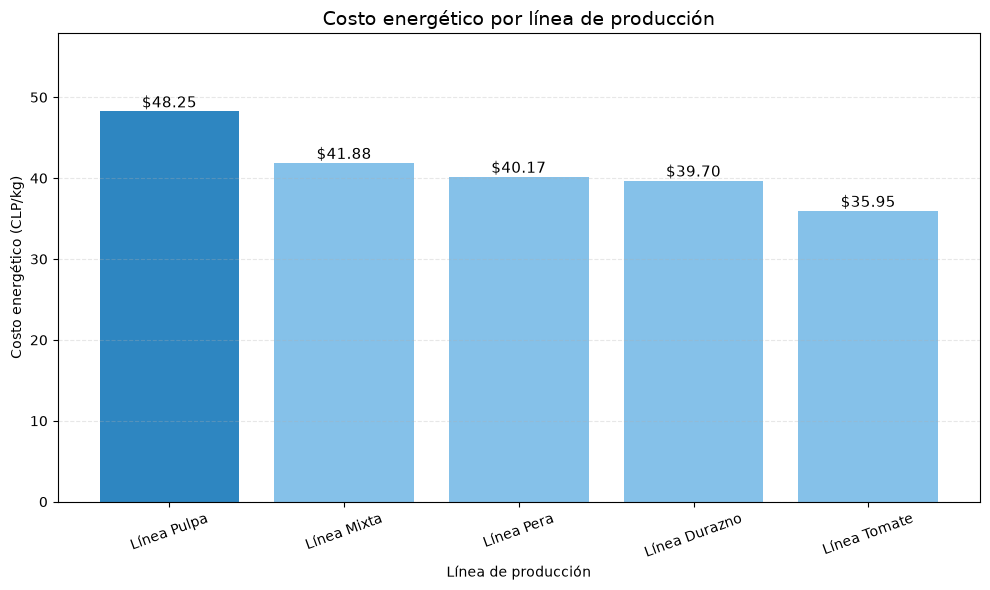

In [43]:
# Grafico
import matplotlib.pyplot as plt

# Ordenar las líneas de mayor a menor costo
resumen_grafico = resumen.sort_values(
    "costo_clp_kg",
    ascending=False
)

# Crear el gráfico
plt.figure(figsize=(10, 6))

barras = plt.bar(
    resumen_grafico["nombre_linea"],
    resumen_grafico["costo_clp_kg"],
    color=["#2E86C1", "#85C1E9", "#85C1E9", "#85C1E9", "#85C1E9"]
)

# Mostrar el valor sobre cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 0.5,
        f"${altura:.2f}",
        ha="center",
        fontsize=11
    )

# Títulos y etiquetas
plt.title("Costo energético por línea de producción", fontsize=14)
plt.xlabel("Línea de producción")
plt.ylabel("Costo energético (CLP/kg)")

plt.ylim(0, resumen_grafico["costo_clp_kg"].max() * 1.2)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


In [44]:
# Comprobar el resultado específico de Pulpa
pulpa = resumen[
    resumen["nombre_linea"] == "Línea Pulpa"
]

display(pulpa)

print(
    "Costo total Pulpa:",
    pulpa["costo_total"].iloc[0]
)

print(
    "Kg totales Pulpa:",
    pulpa["kg_total"].iloc[0]
)

print(
    "CLP/kg Pulpa:",
    pulpa["costo_clp_kg"].iloc[0]
)

,nombre_linea,costo_total,kg_total,ordenes,costo_clp_kg
3,Línea Pulpa,3.418741e+07,708531.99,30,48.251052


Costo total Pulpa: 34187413.9586
Kg totales Pulpa: 708531.99
CLP/kg Pulpa: 48.25105209236918


### Análisis de sensibilidad

Se compararon dos escenarios para evaluar cómo influye la selección de registros en el costo energético por kilogramo.

En el primer escenario se consideraron solamente las órdenes con todos sus cargos válidos. En el segundo, se incluyeron también los cargos válidos de órdenes que presentaban otros cargos en revisión.

Esta comparación permite evaluar si la conclusión sobre la línea más costosa se mantiene al modificar el criterio de selección.

El segundo escenario debe interpretarse con precaución, porque los cargos pendientes de revisión no se incluyen en el costo calculado y podrían aumentar el valor real.

In [45]:
# ESCENARIO A: criterio conservador original

escenario_A = (
    tabla[
        tabla["estado_calculo"] == "calculable"
    ]
    .groupby("nombre_linea")
    .agg(
        costo_A=("costo_clp", "sum"),
        kg_A=("kg_produccion", "sum"),
        ordenes_A=("op_key", "nunique")
    )
)

escenario_A["clp_kg_A"] = (
    escenario_A["costo_A"] /
    escenario_A["kg_A"]
)

# ESCENARIO B: considerar los cargos válidos de órdenes
# con producción válida, aunque tengan otros cargos en revisión

ordenes_B = tabla[
    (tabla["estado_linea_op"] == "una_linea")
    &
    (tabla["kg_produccion"] > 0)
    &
    (tabla["cargos_validos"] > 0)
].copy()

escenario_B = (
    ordenes_B
    .groupby("nombre_linea")
    .agg(
        costo_B=("costo_clp", "sum"),
        kg_B=("kg_produccion", "sum"),
        ordenes_B=("op_key", "nunique")
    )
)

escenario_B["clp_kg_B"] = (
    escenario_B["costo_B"] /
    escenario_B["kg_B"]
)

# Comparación de los resultados

comparacion = escenario_A[
    ["clp_kg_A", "ordenes_A"]
].join(
    escenario_B[
        ["clp_kg_B", "ordenes_B"]
    ],
    how="outer"
)

comparacion["diferencia_clp_kg"] = (
    comparacion["clp_kg_B"] -
    comparacion["clp_kg_A"]
)

display(comparacion.round(2))

# Identificar la línea con mayor costo en cada escenario

print(
    "Mayor costo escenario A:",
    escenario_A["clp_kg_A"].idxmax()
)

print(
    "Mayor costo escenario B:",
    escenario_B["clp_kg_B"].idxmax()
)

# Exportar la comparación
comparacion.to_csv(
    "comparacion_escenarios_duo08.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)


,clp_kg_A,ordenes_A,clp_kg_B,ordenes_B,diferencia_clp_kg
nombre_linea,,,,,
Línea Durazno,39.70,20,35.63,26,-4.07
Línea Mixta,41.88,20,36.70,31,-5.18
Línea Pera,40.17,22,38.30,28,-1.86
Línea Pulpa,48.25,30,46.11,34,-2.14
Línea Tomate,35.95,30,31.69,38,-4.26


Mayor costo escenario A: Línea Pulpa
Mayor costo escenario B: Línea Pulpa


In [46]:
# Buscar órdenes calculables que tengan cargos en USD

candidatas = tabla[
    (tabla["estado_calculo"] == "calculable")
    &
    (tabla["cargos_usd"] > 0)
]

print("Órdenes disponibles para demostrar:")
display(
    candidatas[
        ["op_key", "nombre_linea",
         "costo_clp", "kg_produccion",
         "costo_unitario_clp_kg"]
    ].head()
)

# Seleccionar la primera orden candidata
orden_ejemplo = candidatas.iloc[0]["op_key"]

print("Orden seleccionada:", orden_ejemplo)

# Mostrar sus cargos originales y conversiones
print("\nCARGOS EN A")
display(
    auditoria_cargos[
        auditoria_cargos["op_key"] == orden_ejemplo
    ][[
        "op", "linea", "concepto",
        "monto_original", "moneda",
        "fecha_dolar_usada", "valor_dolar",
        "monto_clp", "estado_cargo"
    ]]
)

# Mostrar sus registros de producción
print("\nPRODUCCIÓN EN B")
display(
    b[b["op_key"] == orden_ejemplo][[
        "id_registro", "ref_op",
        "medida", "unidad",
        "kg", "valida_b"
    ]]
)

# Mostrar el resultado de la orden
print("\nRESULTADO FINAL")
display(
    tabla[tabla["op_key"] == orden_ejemplo][[
        "op_key", "nombre_linea",
        "costo_clp", "kg_produccion",
        "costo_unitario_clp_kg",
        "estado_calculo"
    ]]
)


Órdenes disponibles para demostrar:


,op_key,nombre_linea,costo_clp,kg_produccion,costo_unitario_clp_kg
0,1005,Línea Mixta,8.300639e+05,30163.32,27.518982
2,1011,Línea Pera,9.271554e+05,26767.56,34.637277
3,1017,Línea Mixta,1.604469e+06,33806.39,47.460539
6,1033,Línea Pera,9.724508e+05,26105.74,37.250458
7,1043,Línea Durazno,4.697204e+05,14483.35,32.431753


Orden seleccionada: 1005

CARGOS EN A


,op,linea,concepto,monto_original,moneda,fecha_dolar_usada,valor_dolar,monto_clp,estado_cargo
396,OP-1005,1,Vapor de caldera,"813,95",USD,2026-07-14,922.14,750575.853,Válido
397,OP-1005,2,Electricidad,79488,CLP,2026-07-14,922.14,79488.000,Válido



PRODUCCIÓN EN B


,id_registro,ref_op,medida,unidad,kg,valida_b
370,R-51979,1005,6116.10,kg,6116.10,True
374,R-51981,1005,8407.00,kg,8407.00,True
375,R-51977,1005,10600.62,kg,10600.62,True
377,R-51983,1005,5039.60,kg,5039.60,True



RESULTADO FINAL


,op_key,nombre_linea,costo_clp,kg_produccion,costo_unitario_clp_kg,estado_calculo
0,1005,Línea Mixta,830063.853,30163.32,27.518982,calculable


In [47]:
# Comprobar los totales de control
print("Total de órdenes:", len(tabla))

print(
    "Órdenes calculables:",
    (tabla["estado_calculo"] == "calculable").sum()
)

print(
    "Costo comparable total:",
    resumen["costo_total"].sum()
)

print(
    "Kilos comparables totales:",
    resumen["kg_total"].sum()
)

print(
    "Comprobación de costos:",
    np.isclose(
        resumen["costo_total"].sum(),
        tabla["costo_para_tasa"].sum()
    )
)

print(
    "Comprobación de kilos:",
    np.isclose(
        resumen["kg_total"].sum(),
        tabla["kg_para_tasa"].sum()
    )
)

Total de órdenes: 187
Órdenes calculables: 122
Costo comparable total: 127140770.7029
Kilos comparables totales: 3085091.36
Comprobación de costos: True
Comprobación de kilos: True


In [48]:
# Validación final y exportación
# Comprobar la llave y la estructura
print(
    "Órdenes duplicadas:",
    tabla.duplicated("op_key").sum()
)

print(
    "Órdenes sin línea:",
    tabla["nombre_linea"].isna().sum()
)

print(
    "Órdenes sin pareja en B:",
    (tabla["_merge"] == "left_only").sum()
)

assert tabla["op_key"].is_unique
assert len(tabla) == len(a_agrupado)

print("Validación estructural correcta")

Órdenes duplicadas: 0
Órdenes sin línea: 2
Órdenes sin pareja en B: 22
Validación estructural correcta


In [49]:
# Exportar la tabla analítica
columnas_finales = [
    "op_key",
    "nombre_linea",
    "estado_linea_op",
    "fecha_inicial",
    "fecha_final",
    "lineas_cargo",
    "cargos_validos",
    "cargos_excluidos",
    "costo_clp",
    "registros_b",
    "registros_b_validos",
    "registros_b_excluidos",
    "kg_produccion",
    "estado_calculo",
    "costo_para_tasa",
    "kg_para_tasa",
    "costo_unitario_clp_kg",
    "regla_cambio",
    "regla_costo",
    "procedencia"
]

tabla_analitica = tabla[columnas_finales].copy()

tabla_analitica.to_csv(
    "tabla_analitica_duo08.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    index=False
)

print("Tabla exportada correctamente")
print("Filas:", len(tabla_analitica))

Tabla exportada correctamente
Filas: 187
